# 7. Products, Quotients and Duality
Run the cells in order. Keep `lafp.py` in the same folder.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from lafp import *
%matplotlib inline

The quotient $\R^2/U$ for the line $U$ through $(2,1)$. Each element of the quotient is a whole line parallel to $U$ (several shown, coloured). Adding two such lines adds any of their representatives: $v+U$ plus $w+U$ is $(v+w)+U$, whichever $v$ and $w$ we pick from the lines. The quotient behaves like a one-dimensional space, which can be pictured on any transversal line (dashed), but no transversal is preferred.

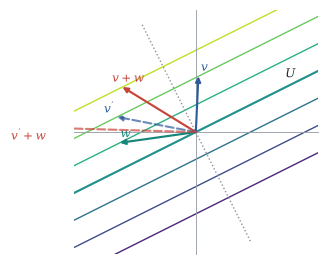

In [2]:
fig, ax = plt.subplots(figsize=(W * 0.62, 2.3))
plane(ax, 3, grid=False)
u = np.array([2.0, 1.0]); n = np.array([-1.0, 2.0]) / np.sqrt(5)
cmap = plt.cm.viridis(np.linspace(0.1, 0.9, 7))
for k, c in zip(range(-3, 4), cmap):
    p = k * 0.6 * n
    t = np.array([-4, 4]); ax.plot(p[0] + t * u[0], p[1] + t * u[1], color=c, lw=1.4 if k == 0 else 0.9)
ax.text(2.2, 1.35, "$U$", fontsize=8)
v = 1.2 * n + 0.3 * u; w = 0.6 * n - 0.8 * u
for vec, lab, col in [(v, "$v$", BLUE), (w, "$w$", TEAL), (v + w, "$v+w$", RED)]:
    arrow(ax, vec, color=col, label=lab, offset=(0.15, 0.2))
v2 = v - 1.0 * u
arrow(ax, v2, color=BLUE, ls="--", alpha=0.7, label="$v'$", offset=(-0.2, 0.2))
arrow(ax, v2 + w, color=RED, ls="--", alpha=0.7, label="$v'+w$", offset=(-0.3, -0.2))
t = np.array([-3, 3]); ax.plot(t * n[0], t * n[1], color=GRAY, ls=":", lw=0.9)

Vectors are arrows, functionals are stacks of parallel lines. The functional $\varphi(x,y)=x+2y$ is drawn through its level lines $\varphi=-3,\dots,3$; the arrow $v=(2,0.5)$ crosses three of them, so $\varphi(v)=3$. Right, $2\varphi$ has lines twice as dense, and the same arrow crosses six.

findfont: Failed to find font weight semibold for DejaVu Serif, now using 700.


findfont: Failed to find font weight semibold for DejaVu Serif, now using 700.


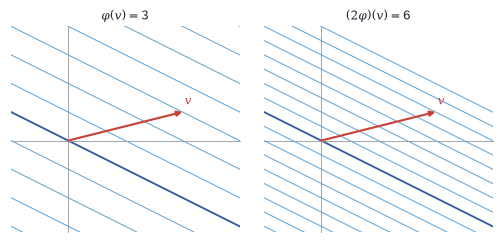

In [3]:
fig, axs = plt.subplots(1, 2, figsize=(W, 2.1))
v = np.array([2.0, 0.5])
for ax, s in zip(axs, [1, 2]):
    plane(ax, (-1, 3, -1.6, 2), grid=False)
    xx = np.linspace(-1, 3, 2)
    for c in np.arange(-8, 9):
        ax.plot(xx, (c / s - xx) / 2, color=SKY if c else BLUE, lw=0.7 if c else 1.2)
    arrow(ax, v, color=RED, label="$v$", offset=(0.1, 0.18))
    ax.set_title(r"$\varphi(v)=3$" if s == 1 else r"$(2\varphi)(v)=6$")

A skewed basis $v_1,v_2$ of $\R^2$ and its dual basis. The level lines of $\varphi_1$ (blue) are parallel to $v_2$ and spaced so that $v_1$ crosses exactly one gap; the level lines of $\varphi_2$ (teal) are parallel to $v_1$. Together they form the coordinate grid of the basis. In matrix terms, if the $v_k$ are the columns of $B$, the dual basis functionals are the rows of $B^{-1}$.

rows of B^{-1} (the dual basis):
 [[ 0.7407 -0.3704]
 [-0.1852  0.9259]]


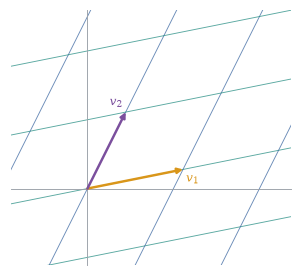

In [4]:
B = np.array([[1.5, 0.6], [0.3, 1.2]])
Binv = np.linalg.inv(B)
fig, ax = plt.subplots(figsize=(W * 0.6, 2.4))
plane(ax, (-1.2, 3.2, -1.2, 2.8), grid=False)
xx = np.linspace(-2, 4, 2)
for c in range(-3, 5):
    for row, col in [(Binv[0], BLUE), (Binv[1], TEAL)]:
        ax.plot(xx, (c - row[0] * xx) / row[1], color=col, lw=0.6, alpha=0.7)
arrow(ax, B[:, 0], color=GOLD, lw=1.6, label="$v_1$", offset=(0.15, -0.15))
arrow(ax, B[:, 1], color=PLUM, lw=1.6, label="$v_2$", offset=(-0.15, 0.15))
print("rows of B^{-1} (the dual basis):\n", Binv.round(4))

The affine hull of three points $v_1,v_2,v_3$ in $\R^3$ (black) is the plane through them (gold), the translate $v_1+\operatorname{span}(v_2-v_1,v_3-v_1)$. It does not pass through the origin; the parallel plane through the origin (blue) is its direction subspace. The triangle is the convex hull, where in addition all $\lambda_k\ge 0$.

[]

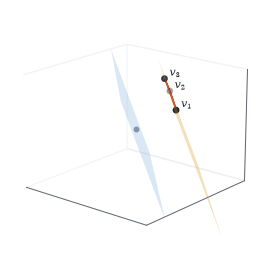

In [5]:
P = np.array([[1.0, 0.2, 0.8], [0.1, 1.1, 0.9], [0.5, 0.4, 1.6]])
nrm = np.cross(P[1] - P[0], P[2] - P[0])
fig = plt.figure(figsize=(W * 0.6, W * 0.5))
ax = ax3d(fig, elev=18, azim=-50, lim=1.8)
plane3d(ax, nrm, nrm @ P[0], lim=1.6, color=GOLD, alpha=0.3)
plane3d(ax, nrm, 0, lim=1.6, color=SKY, alpha=0.25)
ax.add_collection3d(__import__("mpl_toolkits.mplot3d.art3d", fromlist=["Poly3DCollection"]).Poly3DCollection([P], color=RED, alpha=0.35))
ax.scatter(*P.T, color=INK, s=12); ax.scatter(0, 0, 0, color=GRAY, s=8)
for k in range(3):
    ax.text(*(P[k] + 0.08), f"$v_{k+1}$", fontsize=7)
ax.set_xticks([]); ax.set_yticks([]); ax.set_zticks([])

A plane $U$ in $\R^3$ (blue) and the functional $\varphi$ that annihilates it, drawn through three of its level sets $\varphi=-1,0,1$ (the middle one is $U$ itself). Every element of the one-dimensional annihilator $U^0$ is a multiple of $\varphi$; it measures only how far a vector sticks out of $U$.

[]

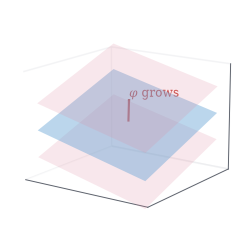

In [6]:
nrm = np.array([0.3, -0.4, 1.0])
fig = plt.figure(figsize=(W * 0.55, W * 0.47))
ax = ax3d(fig, elev=15, azim=-55, lim=1.6)
for c, col, a in [(-0.8, ROSE, 0.2), (0, SKY, 0.45), (0.8, ROSE, 0.2)]:
    plane3d(ax, nrm, c, lim=1.4, color=col, alpha=a)
arrow3d(ax, nrm / np.linalg.norm(nrm) * 0.9, color=RED, label=r"$\varphi$ grows")
ax.set_xticks([]); ax.set_yticks([]); ax.set_zticks([])

In [7]:
rng = np.random.default_rng(0)
T1, T2, T3 = rng.normal(size=(50, 200)), rng.normal(size=(30, 50)), rng.normal(size=(1, 30))
c = np.array([1.0])
grad = T1.T @ (T2.T @ (T3.T @ c))                     # backward pass: dual maps, right to left
f = lambda x: (T3 @ T2 @ T1 @ x)[0]
x0 = rng.normal(size=200)
for _ in range(3):
    h = rng.normal(size=200)
    print(f"directional derivative {f(x0 + h) - f(x0): .6f}   grad . h {grad @ h: .6f}")

directional derivative -571.881623   grad . h -571.881623
directional derivative  68.140080   grad . h  68.140080
directional derivative -252.339171   grad . h -252.339171


In [8]:
from math import comb
t = np.array([0, 1 / 3, 2 / 3, 1])
M = np.array([[comb(3, k) * s ** k * (1 - s) ** (3 - k) for k in range(4)] for s in t])
np.set_printoptions(suppress=True)
print("Bernstein coefficient functionals as combinations of p(0), p(1/3), p(2/3), p(1):\n", np.linalg.inv(M).round(4))

Bernstein coefficient functionals as combinations of p(0), p(1/3), p(2/3), p(1):
 [[ 1.      0.      0.      0.    ]
 [-0.8333  3.     -1.5     0.3333]
 [ 0.3333 -1.5     3.     -0.8333]
 [ 0.      0.      0.      1.    ]]
